# 퀘스트6: 주택 가격 예측 (modulabs-di)
**목표**: 주택의 여러 특성으로 `SalePrice`를 예측하고, RMSE를 최대한 낮추기

진행 순서
1. 데이터 확인 및 불러오기
2. 전처리 (이상치 · 결측치 · 피처 엔지니어링 · 왜도 보정 · 인코딩)
3. 모델 설정 및 학습 (5-Fold 교차검증)
4. 앙상블(블렌딩)
5. 테스트 데이터 예측 및 제출 파일 생성

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from scipy.special import boxcox1p

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LassoCV, ElasticNetCV, RidgeCV
from sklearn.kernel_ridge import KernelRidge
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor

plt.rcParams['axes.unicode_minus'] = False
SEED = 42

## 1. 데이터 확인 및 불러오기

In [2]:
DATA_DIR = 'modulabs-di'
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
print('train:', train.shape, '/ test:', test.shape)
train.head()

train: (1168, 81) / test: (292, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,968,20,RL,NaN,7390,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,135000
1,739,90,RL,60.0,10800,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2009,WD,Alloca,179000
2,696,20,RL,54.0,13811,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,176000
3,239,20,RL,93.0,12030,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2007,New,Partial,318000
4,891,50,RL,60.0,8064,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,2000,7,2007,WD,Normal,122900


In [3]:
train['SalePrice'].describe()

count      1168.000000
mean     180194.401541
std       78869.201529
min       34900.000000
25%      129500.000000
50%      163995.000000
75%      213062.500000
max      755000.000000
Name: SalePrice, dtype: float64

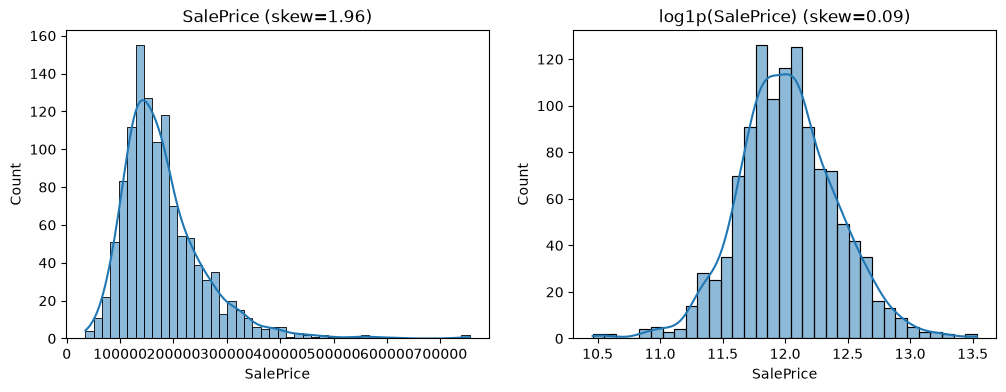

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train['SalePrice'], kde=True, ax=ax[0]).set_title(f"SalePrice (skew={train['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(train['SalePrice']), kde=True, ax=ax[1]).set_title(f"log1p(SalePrice) (skew={np.log1p(train['SalePrice']).skew():.2f})")
plt.show()

타깃이 오른쪽으로 치우쳐 있으므로 **`log1p` 변환한 값으로 학습**하고, 예측 후 `expm1`로 되돌립니다. 비싼 집의 큰 오차에 끌려가지 않아 전체 RMSE가 안정적으로 낮아집니다.

In [5]:
# 타깃과 상관관계가 높은 수치형 변수
corr = train.select_dtypes('number').corr()['SalePrice'].sort_values(ascending=False)
corr.head(11)

SalePrice       1.000000
OverallQual     0.785111
GrLivArea       0.710178
GarageCars      0.632622
GarageArea      0.618311
1stFlrSF        0.597729
TotalBsmtSF     0.595882
FullBath        0.577860
TotRmsAbvGrd    0.548795
YearRemodAdd    0.504817
YearBuilt       0.501762
Name: SalePrice, dtype: float64

In [6]:
# 결측치 현황 (train + test)
na = pd.concat([train.drop(columns='SalePrice'), test]).isnull().sum()
na = na[na > 0].sort_values(ascending=False)
pd.DataFrame({'결측 수': na, '비율(%)': (na / (len(train) + len(test)) * 100).round(1)})

,결측 수,비율(%)
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


## 2. 전처리
### 2-1. 이상치 처리

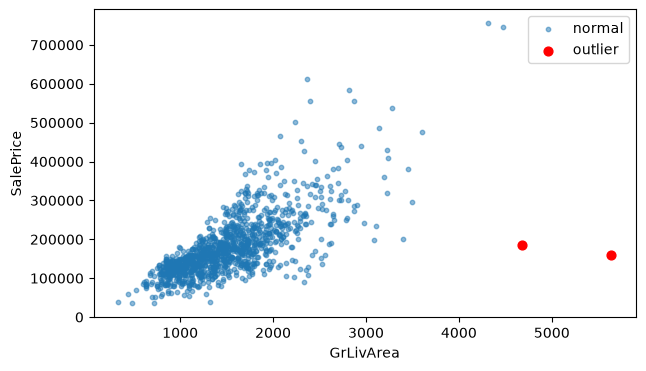

,Id,GrLivArea,OverallQual,SalePrice
64,1299,5642,10,160000
373,524,4676,10,184750


In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
out_mask = (train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)
ax.scatter(train['GrLivArea'], train['SalePrice'], s=10, alpha=.5, label='normal')
ax.scatter(train.loc[out_mask, 'GrLivArea'], train.loc[out_mask, 'SalePrice'], s=40, c='red', label='outlier')
ax.set_xlabel('GrLivArea'); ax.set_ylabel('SalePrice'); ax.legend()
plt.show()
train.loc[out_mask, ['Id', 'GrLivArea', 'OverallQual', 'SalePrice']]

면적이 4000 sqft를 넘는데 가격이 매우 낮은 2개 행은 일반적인 추세(면적↑ → 가격↑)를 크게 벗어나 회귀선을 왜곡하므로 제거합니다.

In [8]:
train = train[~out_mask].reset_index(drop=True)
y = np.log1p(train['SalePrice'].values)

test_id = test['Id']
n_train = len(train)
all_df = pd.concat([train.drop(columns='SalePrice'), test]).reset_index(drop=True).drop(columns='Id')
print('train 행 수:', n_train, '/ 합친 데이터:', all_df.shape)

train 행 수: 1166 / 합친 데이터: (1458, 79)


### 2-2. 결측치 처리
- **'없음'을 뜻하는 NaN** (수영장·차고·지하실 등 시설 없음) → 범주형은 `'None'`, 수치형은 `0`
- **LotFrontage** → 같은 동네(Neighborhood)의 중앙값
- 나머지 범주형 → 최빈값, 수치형 → 중앙값
- `Utilities`는 거의 모든 값이 동일해 정보가 없으므로 제거

In [9]:
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
             'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
all_df[none_cols] = all_df[none_cols].fillna('None')
all_df[zero_cols] = all_df[zero_cols].fillna(0)

all_df['LotFrontage'] = all_df.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
all_df = all_df.drop(columns='Utilities')

for c in all_df.columns:
    if pd.api.types.is_numeric_dtype(all_df[c]):
        all_df[c] = all_df[c].fillna(all_df[c].median())
    else:
        all_df[c] = all_df[c].fillna(all_df[c].mode()[0])

print('남은 결측치:', all_df.isnull().sum().sum())

남은 결측치: 0


### 2-3. 피처 엔지니어링
- **순서형 등급 → 숫자** (Po < Fa < TA < Gd < Ex 등): 품질의 크기 관계를 모델이 활용할 수 있게
- **파생 변수**: 총면적, 총 욕실 수, 집 나이, 품질×면적 등
- `MSSubClass`, `MoSold`, `YrSold`는 숫자지만 실제로는 범주이므로 문자열로 변환

In [10]:
qual = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual',
          'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']:
    all_df[c + '_n'] = all_df[c].map(qual).fillna(0)
fin = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
all_df['BsmtFinType1_n'] = all_df['BsmtFinType1'].map(fin).fillna(0)
all_df['BsmtFinType2_n'] = all_df['BsmtFinType2'].map(fin).fillna(0)
all_df['BsmtExposure_n'] = all_df['BsmtExposure'].map({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}).fillna(0)
all_df['GarageFinish_n'] = all_df['GarageFinish'].map({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}).fillna(0)
all_df['Functional_n'] = all_df['Functional'].map({'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4,
                                                   'Min2': 5, 'Min1': 6, 'Typ': 7}).fillna(7)

all_df['TotalSF'] = all_df['TotalBsmtSF'] + all_df['1stFlrSF'] + all_df['2ndFlrSF']
all_df['TotalBath'] = (all_df['FullBath'] + 0.5 * all_df['HalfBath']
                       + all_df['BsmtFullBath'] + 0.5 * all_df['BsmtHalfBath'])
all_df['TotalPorch'] = (all_df['OpenPorchSF'] + all_df['EnclosedPorch'] + all_df['3SsnPorch']
                        + all_df['ScreenPorch'] + all_df['WoodDeckSF'])
all_df['HouseAge'] = all_df['YrSold'] - all_df['YearBuilt']
all_df['RemodAge'] = all_df['YrSold'] - all_df['YearRemodAdd']
all_df['QualSF'] = all_df['OverallQual'] * all_df['GrLivArea']
all_df['QualTotSF'] = all_df['OverallQual'] * all_df['TotalSF']
all_df['HasPool'] = (all_df['PoolArea'] > 0).astype(int)
all_df['Has2nd'] = (all_df['2ndFlrSF'] > 0).astype(int)
all_df['HasGarage'] = (all_df['GarageArea'] > 0).astype(int)
all_df['HasBsmt'] = (all_df['TotalBsmtSF'] > 0).astype(int)
all_df['HasFireplace'] = (all_df['Fireplaces'] > 0).astype(int)

for c in ['MSSubClass', 'MoSold', 'YrSold']:
    all_df[c] = all_df[c].astype(str)
print(all_df.shape)

(1458, 105)


### 2-4. 왜도 보정 & 원-핫 인코딩
왜도(|skew| > 0.75)가 큰 수치형 변수는 Box-Cox(λ=0.15) 변환으로 분포를 정규분포에 가깝게 만들어 선형 모델 성능을 높입니다.

In [11]:
num_cols = all_df.select_dtypes('number').columns
skewness = all_df[num_cols].apply(lambda s: skew(s)).abs().sort_values(ascending=False)
skewed = skewness[skewness > 0.75].index
for c in skewed:
    all_df[c] = boxcox1p(all_df[c].clip(lower=0), 0.15)
print('Box-Cox 변환 변수 수:', len(skewed))

X_all = pd.get_dummies(all_df).astype(float)
X = X_all.iloc[:n_train].values
X_test = X_all.iloc[n_train:].values
print('X:', X.shape, '/ X_test:', X_test.shape)

Box-Cox 변환 변수 수: 37
X: (1166, 355) / X_test: (292, 355)


## 3. 모델 설정 및 학습
서로 성격이 다른 6개 모델을 5-Fold 교차검증으로 평가합니다. 선형 계열 모델은 이상치에 강한 `RobustScaler`로 스케일링합니다.

| 모델 | 특징 |
|---|---|
| Lasso / ElasticNet | L1 규제로 불필요한 변수 제거 (변수 355개에 효과적) |
| Ridge | L2 규제 |
| KernelRidge | 2차 다항 커널 → 변수 간 상호작용 반영 |
| SVR | RBF 커널, 비선형 관계 |
| GradientBoosting | 트리 기반, huber loss로 이상치에 강건 |

In [12]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
alphas = np.logspace(-4.5, -2, 40)

models = {
    'Lasso': make_pipeline(RobustScaler(), LassoCV(alphas=alphas, max_iter=50000, cv=5)),
    'ElasticNet': make_pipeline(RobustScaler(), ElasticNetCV(l1_ratio=[.3, .5, .8], alphas=alphas,
                                                            max_iter=50000, cv=5)),
    'Ridge': make_pipeline(RobustScaler(), RidgeCV(alphas=np.logspace(-1, 2.5, 40))),
    'KernelRidge': make_pipeline(RobustScaler(), KernelRidge(alpha=0.6, kernel='polynomial',
                                                             degree=2, coef0=2.5)),
    'SVR': make_pipeline(RobustScaler(), SVR(C=20, epsilon=0.008, gamma=0.0003)),
    'GBR': GradientBoostingRegressor(n_estimators=3000, learning_rate=0.02, max_depth=4,
                                     max_features='sqrt', min_samples_leaf=15, min_samples_split=10,
                                     loss='huber', subsample=0.8, random_state=SEED),
}

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

oof, scores = {}, []
for name, model in models.items():
    oof[name] = cross_val_predict(model, X, y, cv=kf, n_jobs=-1)
    scores.append({'model': name,
                   'log RMSE': rmse(y, oof[name]),
                   'RMSE (가격)': rmse(np.expm1(y), np.expm1(oof[name]))})
    print(f"{name:12s} log RMSE {scores[-1]['log RMSE']:.4f} | RMSE {scores[-1]['RMSE (가격)']:,.0f}")

Lasso        log RMSE 0.1109 | RMSE 21,693


ElasticNet   log RMSE 0.1109 | RMSE 21,652


Ridge        log RMSE 0.1157 | RMSE 21,731


KernelRidge  log RMSE 0.1189 | RMSE 21,480


SVR          log RMSE 0.1141 | RMSE 20,108


GBR          log RMSE 0.1158 | RMSE 22,533


## 4. 앙상블 (블렌딩)
각 모델의 오차 패턴이 다르기 때문에 가중 평균하면 단일 모델보다 RMSE가 더 낮아집니다.

,log RMSE,RMSE (가격)
model,,
SVR,0.1141,"20,108"
Blend,0.1090,"20,831"
KernelRidge,0.1189,"21,480"
ElasticNet,0.1109,"21,652"
Lasso,0.1109,"21,693"
Ridge,0.1157,"21,731"
GBR,0.1158,"22,533"


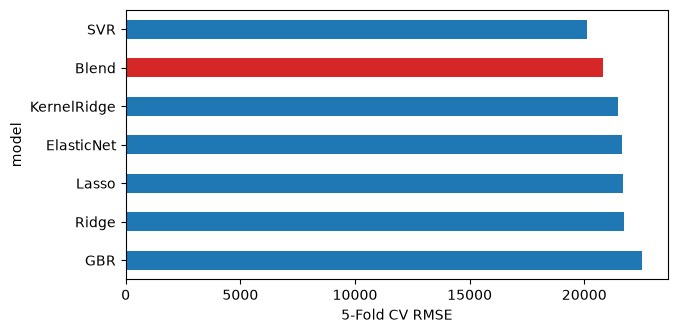

In [13]:
weights = {'Lasso': .20, 'ElasticNet': .15, 'Ridge': .10, 'KernelRidge': .10, 'SVR': .15, 'GBR': .30}
blend_oof = sum(w * oof[k] for k, w in weights.items())
scores.append({'model': 'Blend', 'log RMSE': rmse(y, blend_oof),
               'RMSE (가격)': rmse(np.expm1(y), np.expm1(blend_oof))})

score_df = pd.DataFrame(scores).set_index('model').sort_values('RMSE (가격)')
display(score_df.style.format({'log RMSE': '{:.4f}', 'RMSE (가격)': '{:,.0f}'}))

score_df['RMSE (가격)'].plot.barh(figsize=(7, 3.5), color=['tab:red' if i == 'Blend' else 'tab:blue' for i in score_df.index])
plt.gca().invert_yaxis(); plt.xlabel('5-Fold CV RMSE'); plt.show()

## 5. 테스트 데이터 예측 및 제출
전체 train 데이터로 각 모델을 다시 학습한 뒤, 같은 가중치로 블렌딩하고 `expm1`으로 원래 가격 단위로 되돌립니다.

In [14]:
test_pred = {}
for name, model in models.items():
    model.fit(X, y)
    test_pred[name] = model.predict(X_test)

blend_test = np.expm1(sum(w * test_pred[k] for k, w in weights.items()))

submission = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
submission['SalePrice'] = pd.Series(blend_test, index=test_id).loc[submission['Id']].values
submission.to_csv('submission_quest6.csv', index=False)
print(submission.shape)
submission.head()

(292, 2)


,Id,SalePrice
0,86,262313.911156
1,227,262479.676628
2,492,142683.566981
3,64,136487.184306
4,576,113316.869839


In [15]:
submission['SalePrice'].describe()

count       292.000000
mean     179959.035748
std       74797.260541
min       55561.946191
25%      129967.748547
50%      161071.394948
75%      212883.038506
max      539211.021112
Name: SalePrice, dtype: float64

## 정리
- 타깃 `log1p` 변환, 큰 면적·저가 이상치 2건 제거
- 결측치는 의미에 맞게 처리 ('없음' → None/0, LotFrontage → 동네 중앙값)
- 순서형 인코딩 + 파생변수 + Box-Cox로 선형 모델이 학습하기 좋은 형태로 변환
- 6개 모델 블렌딩으로 단일 모델보다 낮은 CV RMSE 달성 → `submission_quest6.csv` 제출